# Simple calculations

A first pass through `azoth-engine`: a pipe, a pump and a wall. Calls take `pint` quantities,
return frozen results, and every result carries its own warnings and provenance.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

import azoth
import azoth.hydraulics
import azoth.thermal

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.alpha": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2.0,
        "font.size": 9,
        "figure.figsize": (6.4, 3.4),
    }
)

q = azoth.ureg.Quantity
print("azoth", azoth.__version__, "| backends", sorted(azoth.backends()))

azoth 0.1.3 | backends ['python', 'rust']


## A pipe

A dimensioned input is a `Quantity`. A bare number where a length is expected is refused with
`UnitMismatchError`, so a unit mistake is caught at the call rather than in the answer.

In [2]:
rho = q(998.0, "kg/m**3")
mu = q(1.002e-3, "Pa*s")
D = q(0.1, "m")
v = q(1.5, "m/s")

re = azoth.hydraulics.reynolds_number(rho, v, D, mu)
print(f"Re = {re.re:,.0f}  ({re.regime})")
print("clean:", re.is_clean)

Re = 149,401  (turbulent)
clean: True


## Three friction factors

Colebrook is implicit, Swamee-Jain and Haaland are explicit approximations. At
`Re = 1.5e5` and a relative roughness of `4.5e-4` they agree to about 1.5%.

In [3]:
eps_D = 4.5e-4
for name, fn in [
    ("Colebrook", azoth.hydraulics.friction_factor_colebrook),
    ("Swamee-Jain", azoth.hydraulics.friction_factor_swamee_jain),
    ("Haaland", azoth.hydraulics.friction_factor_haaland),
]:
    print(f"{name:<12} f = {fn(re.re, eps_D).f:.6f}")

Colebrook    f = 0.019138
Swamee-Jain  f = 0.019233
Haaland      f = 0.018915


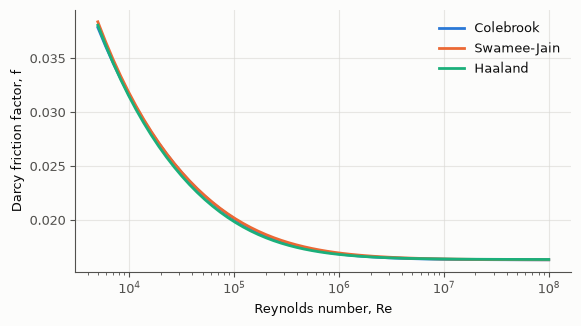

In [4]:
reynolds = np.logspace(3.7, 8.0, 60)
fig, ax = plt.subplots()
for name, fn, colour in [
    ("Colebrook", azoth.hydraulics.friction_factor_colebrook, PALETTE[0]),
    ("Swamee-Jain", azoth.hydraulics.friction_factor_swamee_jain, PALETTE[1]),
    ("Haaland", azoth.hydraulics.friction_factor_haaland, PALETTE[2]),
]:
    ax.plot(reynolds, [fn(float(r), eps_D).f for r in reynolds], color=colour, label=name)
ax.set_xscale("log")
ax.set_xlabel("Reynolds number, Re")
ax.set_ylabel("Darcy friction factor, f")
ax.legend(frameon=False)
plt.show()
plt.close(fig)

## Darcy-Weisbach

The pressure drop over 100 m of the same line. `mu` is optional: without it the Reynolds
number and regime cannot be computed, and the result says so rather than quietly omitting them.

In [5]:
L = q(100.0, "m")
dp = azoth.hydraulics.darcy_weisbach(0.02, L, D, rho, v, mu)
print(f"pressure drop: {dp.dp.to('kPa').magnitude:.2f} kPa")
print(f"Re = {dp.re:,.0f}  ({dp.regime})")
print("clean:", dp.is_clean)

pressure drop: 22.46 kPa
Re = 149,401  (turbulent)
clean: True


In [6]:
no_mu = azoth.hydraulics.darcy_weisbach(0.02, L, D, rho, v)
print(f"pressure drop: {no_mu.dp.to('kPa').magnitude:.2f} kPa")
print("warnings:", [warning.code.value for warning in no_mu.warnings])
print("skipped checks:", no_mu.provenance.skipped_checks)
print("verification:", no_mu.provenance.verification)

pressure drop: 22.46 kPa
warnings: ['RANGE_CHECK_SKIPPED']
skipped checks: ('re',)
verification: source_needed


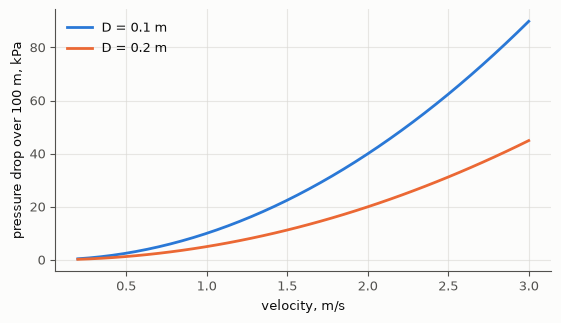

In [7]:
velocities = np.linspace(0.2, 3.0, 40)
fig, ax = plt.subplots()
for diameter, colour in [(0.1, PALETTE[0]), (0.2, PALETTE[1])]:
    drops = [
        azoth.hydraulics.darcy_weisbach(0.02, L, q(diameter, "m"), rho, q(float(speed), "m/s"), mu)
        .dp.to("kPa")
        .magnitude
        for speed in velocities
    ]
    ax.plot(velocities, drops, color=colour, label=f"D = {diameter:.1f} m")
ax.set_xlabel("velocity, m/s")
ax.set_ylabel("pressure drop over 100 m, kPa")
ax.legend(frameon=False)
plt.show()
plt.close(fig)

## A pump and a wall

`pump_power` takes the volumetric flow and the head; `conduction_plane_wall` takes a
temperature *difference*.

In [8]:
pump = azoth.hydraulics.pump_power(rho, q(0.02, "m**3/s"), q(30.0, "m"), 0.72)
print(f"pump shaft power: {pump.power.to('kW').magnitude:.2f} kW")

wall = azoth.thermal.conduction_plane_wall(
    q(0.6, "W/(m*K)"), q(12.0, "m**2"), q(30.0, "delta_degC"), q(0.2, "m")
)
print(f"wall heat flow: {wall.q.to('kW').magnitude:.2f} kW")

pump shaft power: 8.16 kW
wall heat flow: 1.08 kW


In [9]:
try:
    azoth.thermal.conduction_plane_wall(
        q(0.6, "W/(m*K)"), q(12.0, "m**2"), q(30.0, "degC"), q(0.2, "m")
    )
except azoth.UnitMismatchError as error:
    print(type(error).__name__ + ":", error)

UnitMismatchError: `dT` must be a quantity convertible to 'K', got "degree_Celsius (an absolute temperature; this input is a temperature difference, so pass `delta_degC`/`delta_degF`, or convert explicitly with `.to('K')` first)"


## What the number rests on

`to_json()` includes a `provenance` block: the spec and both kernels with their hashes, the
source the equation is attributed to, and how far this call's answer is externally checked.

In [10]:
document = json.loads(no_mu.to_json())
print(json.dumps(document["provenance"], indent=2))

{
  "calc_id": "hydraulics.darcy_weisbach",
  "clean": false,
  "name": "Darcy-Weisbach pressure drop",
  "python_path": "python/src/azoth/hydraulics/reference/darcy_weisbach.py",
  "python_sha256": "bc58e0c3099a8a3d2d455051e79f7f740048e760ccc66ea50e5a4943416601ec",
  "rust_path": "crates/azoth-hydraulics/src/darcy_weisbach.rs",
  "rust_sha256": "545fbab9e66481f673f2c8fba273fabdcaed2d20cf2b9ab33aa063996739915c",
  "skipped_checks": [
    "re"
  ],
  "source": "Crane TP-410",
  "spec_path": "specs/calcs/hydraulics/darcy_weisbach.toml",
  "spec_sha256": "034066c6179089039cb53a2cf080e9e4da82926dc1f05caabf506caf392aa2c0",
  "tests_active": 4,
  "tests_skipped": 2,
  "validation_cases": 1,
  "verification": "source_needed",
  "warning_codes": [
    "RANGE_CHECK_SKIPPED"
  ]
}


## Next

- [Reading a calculation page](https://patrickmockridge.github.io/azoth/manual/using/reading-a-calculation.html)
  explains the sections behind each generated reference page.
- [Python scripting and Jupyter](https://patrickmockridge.github.io/azoth/manual/using/python.html)
  is the manual page these notebooks are examples for.